# figure 4
radiation effect of smoke at harvard forest, our regression against the gu et al. 2003 model (results from 4_gu_model)

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7, "xtick.labelsize": 6, "ytick.labelsize": 6,
    "legend.fontsize": 6, "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "pdf.fonttype": 42, "axes.titlelocation": "left"})
mm = 1 / 25.4
minus = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}".replace("-", "−"))
Path("figures").mkdir(exist_ok=True)
plt.rcParams["axes.titlelocation"] = "center"
days = pd.read_csv("results/gu_days.csv")
summary = pd.read_csv("results/gu_summary.csv", index_col="model").pct
cases = [("regression", "Our\nregression", "#70a0cd"),
         ("gu_default", "Gu default,\nclear sky,\n1992 Albany\nradiation", "#000000"),
         ("gu_clear", "Gu refit,\nclear sky\n(tower\nradiation)", "#c47900"),
         ("gu_partly", "Gu refit,\nclear + partly\ncloudy (tower\nradiation)", "#004f00"),
         ("gu_wx", "Gu refit,\nclear + partly\ncloudy, with\nweather terms", "#003466")]

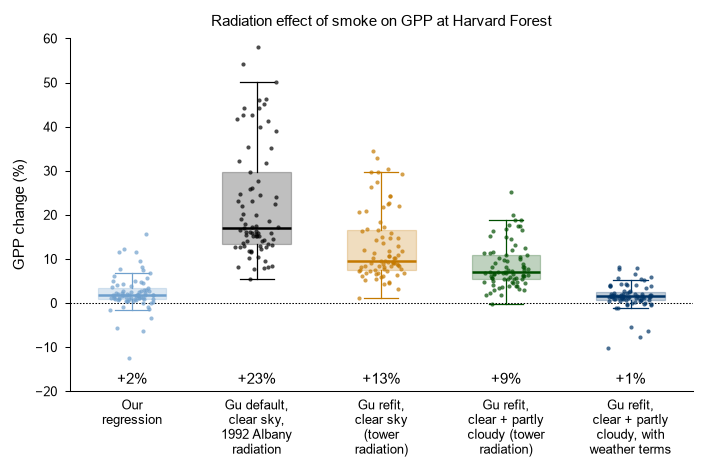

In [2]:
rng = np.random.default_rng(3)
fig, ax = plt.subplots(figsize=(120 * mm, 80 * mm))
for i, (k, lab, col) in enumerate(cases):
    v = days[k]
    ax.boxplot(v, positions=[i], widths=0.55, patch_artist=True, showfliers=False,
               boxprops=dict(facecolor=col, alpha=0.25, edgecolor=col, lw=0.6), medianprops=dict(color=col, lw=1.2),
               whiskerprops=dict(color=col, lw=0.6), capprops=dict(color=col, lw=0.6))
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=4, color=col, alpha=0.7, lw=0, zorder=3)
    ax.text(i, -19, f"{summary[k]:+.0f}%".replace("-", "−"), ha="center", va="bottom")
ax.axhline(0, color="black", lw=0.5, ls=(0, (1.5, 1.5)), zorder=1)
ax.set_xticks(range(len(cases))); ax.set_xticklabels([c[1] for c in cases]); ax.tick_params(axis="x", length=0)
ax.set_ylim(-20, 60); ax.set_ylabel("GPP change (%)")
ax.set_title("Radiation effect of smoke on GPP at Harvard Forest")
fig.tight_layout()
fig.savefig("figures/fig4_harvard_gu.png", dpi=600)